# Analytics Report and Insights: Global Superstore
**Name:** Arifa Begum R  |  **Task 5:** Analytics Report & Insights Documentation

## 1. Business Objective
**Business problem:** a global retailer is growing fast, but about one in four order lines loses money. Leadership wants to know where the business makes and loses money, and what to do next.

**Key questions**
1. How is the business performing overall (sales, profit, margin, growth)?
2. Which products, markets and customers create profit, and which lose it?
3. What drives the losses, and how big is the opportunity?
4. What should the business do, in what order?

**Audience:** Sales Director, Finance Head and Regional Managers.

**Data:** Global Superstore (Kaggle), 51,290 order lines, 2011 to 2014. Note: each row is one order line, and one order can have several lines.

**KPIs tracked:** sales, profit, profit margin, unique orders, customers and the share of loss-making lines.

In [4]:
!mamba install  pandas matplotlib seaborn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.758 seconds
All requested packages already installed.


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

path = Path("data/Global_Superstore2.csv")
if not path.exists():
    path = Path("Global_Superstore2.csv")

raw = pd.read_csv(path, encoding="latin-1")

# Clean: drop unused columns, tidy names, fix dates, add helper columns
df = raw.drop(columns=["Postal Code", "Row ID"])
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_").str.replace("-", "_")
df["order_date"] = pd.to_datetime(df["order_date"], format="%d-%m-%Y")
df["ship_date"] = pd.to_datetime(df["ship_date"], format="%d-%m-%Y")
df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.month
df["delivery_days"] = (df["ship_date"] - df["order_date"]).dt.days
df["is_loss"] = (df["profit"] < 0).astype(int)
df["discount_band"] = pd.cut(df["discount"], bins=[-0.01, 0, 0.2, 0.4, 1],
                             labels=["No discount", "Low (0-20%)", "Medium (20-40%)", "High (>40%)"])

print("Order lines:", len(df), "| Columns:", df.shape[1])
print("Missing values:", int(df.isnull().sum().sum()), "| Duplicate rows:", int(df.duplicated().sum()))
print("Period:", df["order_date"].min().date(), "to", df["order_date"].max().date())

Order lines: 51290 | Columns: 27
Missing values: 0 | Duplicate rows: 0
Period: 2011-01-01 to 2014-12-31


## 2. Performance Overview (KPI Dashboard)

In [6]:
kpis = pd.Series({
    "Sales": df["sales"].sum(),
    "Profit": df["profit"].sum(),
    "Profit margin (%)": df["profit"].sum() / df["sales"].sum() * 100,
    "Unique orders": df["order_id"].nunique(),
    "Order lines": len(df),
    "Customers": df["customer_id"].nunique(),
    "Loss-making lines (%)": df["is_loss"].mean() * 100,
}).round(1)
kpis

Sales                    12642501.9
Profit                    1467457.3
Profit margin (%)              11.6
Unique orders               25035.0
Order lines                 51290.0
Customers                    1590.0
Loss-making lines (%)          24.5
dtype: float64

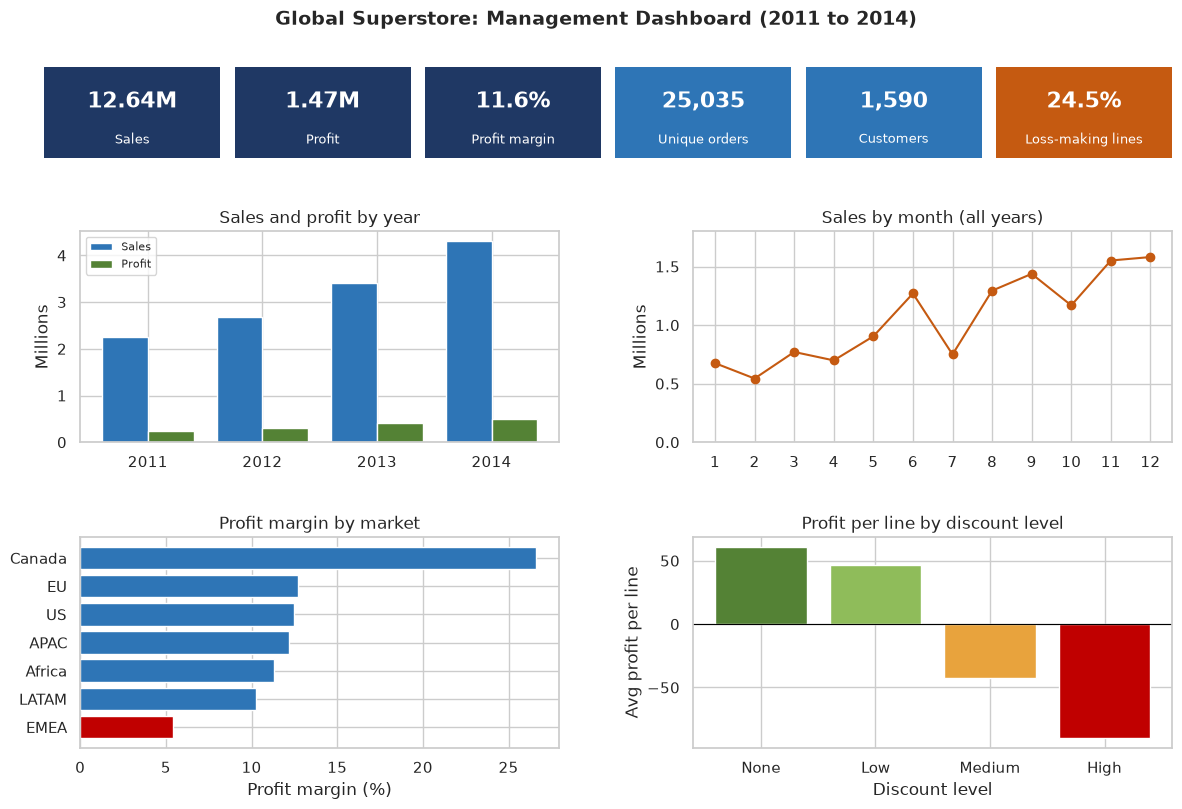

In [7]:
yearly = df.groupby("year")[["sales", "profit"]].sum()
monthly = df.groupby("month")[["sales", "profit"]].sum()
market = df.groupby("market")[["sales", "profit"]].sum()
market["margin"] = market["profit"] / market["sales"] * 100
band_avg = df.groupby("discount_band", observed=True)["profit"].mean()

fig = plt.figure(figsize=(12, 8.2))
top = fig.add_gridspec(1, 6, left=0.04, right=0.98, top=0.9, bottom=0.79, wspace=0.08)
bot = fig.add_gridspec(2, 2, left=0.07, right=0.98, top=0.7, bottom=0.07, hspace=0.45, wspace=0.28)

tiles = [("Sales", f"{df['sales'].sum()/1e6:.2f}M"),
         ("Profit", f"{df['profit'].sum()/1e6:.2f}M"),
         ("Profit margin", f"{df['profit'].sum()/df['sales'].sum()*100:.1f}%"),
         ("Unique orders", f"{df['order_id'].nunique():,}"),
         ("Customers", f"{df['customer_id'].nunique():,}"),
         ("Loss-making lines", f"{df['is_loss'].mean()*100:.1f}%")]
for i, (label, value) in enumerate(tiles):
    ax = fig.add_subplot(top[0, i]); ax.axis("off")
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes,
                               color="#1F3864" if i < 3 else "#C55A11" if i == 5 else "#2E75B6"))
    ax.text(0.5, 0.62, value, ha="center", va="center", color="white", fontsize=16, fontweight="bold", transform=ax.transAxes)
    ax.text(0.5, 0.2, label, ha="center", va="center", color="white", fontsize=9, transform=ax.transAxes)

ax1 = fig.add_subplot(bot[0, 0])
x = np.arange(len(yearly)); ax1.bar(x - 0.2, yearly["sales"] / 1e6, 0.4, label="Sales", color="#2E75B6")
ax1.bar(x + 0.2, yearly["profit"] / 1e6, 0.4, label="Profit", color="#548235")
ax1.set_xticks(x); ax1.set_xticklabels(yearly.index); ax1.set_ylabel("Millions"); ax1.set_title("Sales and profit by year"); ax1.legend(fontsize=8)

ax2 = fig.add_subplot(bot[0, 1])
ax2.plot(monthly.index, monthly["sales"] / 1e6, marker="o", color="#C55A11")
ax2.set_xticks(range(1, 13)); ax2.set_ylim(0, 1.8); ax2.set_ylabel("Millions"); ax2.set_title("Sales by month (all years)")

ax3 = fig.add_subplot(bot[1, 0])
m = market.sort_values("margin")
ax3.barh(m.index, m["margin"], color=["#C00000" if v < 8 else "#2E75B6" for v in m["margin"]])
ax3.set_xlabel("Profit margin (%)"); ax3.set_title("Profit margin by market")

ax4 = fig.add_subplot(bot[1, 1])
ax4.bar(range(4), band_avg.values, color=["#548235", "#8FBC5A", "#E8A33D", "#C00000"])
ax4.axhline(0, color="black", linewidth=0.8)
ax4.set_xticks(range(4)); ax4.set_xticklabels(["None", "Low", "Medium", "High"])
ax4.set_xlabel("Discount level"); ax4.set_ylabel("Avg profit per line"); ax4.set_title("Profit per line by discount level")

fig.suptitle("Global Superstore: Management Dashboard (2011 to 2014)", fontsize=14, fontweight="bold", y=0.97)
plt.show()

**Insight (dashboard):**
- The business sold 12.64M and made a profit of 1.47M, a margin of 11.6%. The 51,290 rows in the data are order lines: they belong to 25,035 unique orders (about 2 lines per order) from 1,590 customers.
- Sales grew 90% and profit grew 102% from 2011 to 2014, so the margin improved slightly (from 11.0% to 11.7%). The business is growing in a healthy way overall.
- But 24.5% of order lines lose money. That is the main area that needs attention, and the next sections look for the reason.

## 3. Trends and Seasonality

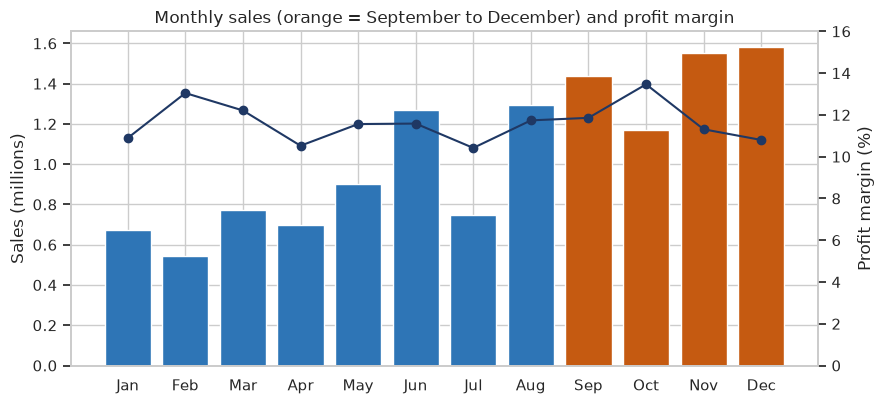

September to December share of sales: 45.4%
            sales     profit  avg_discount  margin
month                                             
1       675133.67   73535.38          0.14   10.89
2       543739.38   70932.20          0.14   13.05
3       770500.94   94087.52          0.14   12.21
4       698561.21   73513.63          0.15   10.52
5       904012.34  104509.78          0.14   11.56
6      1269716.75  147079.42          0.15   11.58
7       749381.84   78070.09          0.15   10.42
8      1293833.17  151854.11          0.13   11.74
9      1437380.11  170438.18          0.14   11.86
10     1168184.39  157269.36          0.14   13.46
11     1551277.34  175449.48          0.14   11.31
12     1580780.77  170718.13          0.15   10.80


In [8]:
monthly = df.groupby("month").agg(sales=("sales", "sum"), profit=("profit", "sum"),
                                  avg_discount=("discount", "mean"))
monthly["margin"] = monthly["profit"] / monthly["sales"] * 100

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(monthly.index, monthly["sales"] / 1e6, color=["#C55A11" if m >= 9 else "#2E75B6" for m in monthly.index])
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("Sales (millions)"); ax.set_title("Monthly sales (orange = September to December) and profit margin")
ax2 = ax.twinx(); ax2.plot(monthly.index, monthly["margin"], color="#1F3864", marker="o"); ax2.set_ylabel("Profit margin (%)"); ax2.set_ylim(0, 16); ax2.grid(False)
plt.tight_layout(); plt.show()

peak = df[df["month"] >= 9]["sales"].sum() / df["sales"].sum() * 100
print(f"September to December share of sales: {peak:.1f}%")
print(monthly.round(2))

**Insight (seasonality):**
- September to December bring 45.4% of yearly sales (5.74M), and November and December alone bring 24.8%. February is the weakest month (0.54M) and December the strongest (1.58M).
- The margin is best in October (13.5%) and weakest in July (10.4%). Margin does not rise in the busiest months, so higher volume does not mean better profit.
- The average discount stays between 13.4% and 15.0% every month, and about 20% to 24% of lines have a discount above 20% in every month. Discounting is a year-round habit, not a seasonal sales tool.

## 4. Product Performance

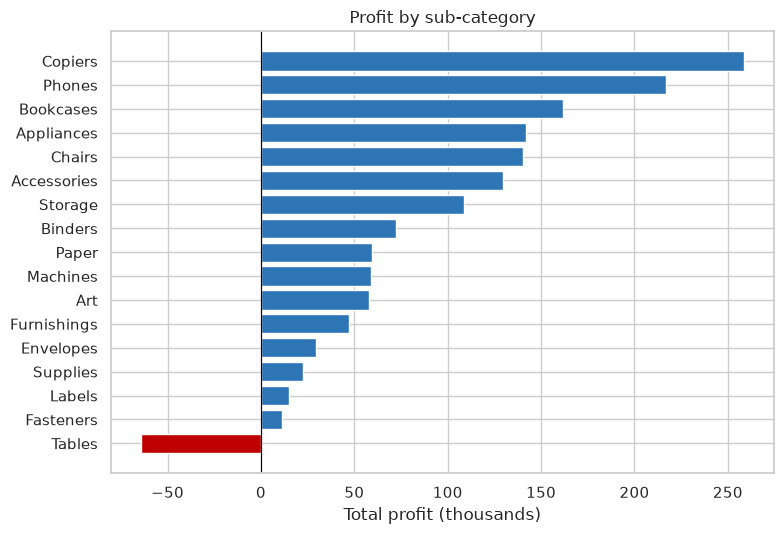

,sales,profit,margin %
sub_category,,,
Copiers,1509436.0,258568.0,17.1
Phones,1706824.0,216717.0,12.7
Bookcases,1466572.0,161924.0,11.0
Appliances,1011064.0,141681.0,14.0
Chairs,1501682.0,140396.0,9.3
Accessories,749237.0,129626.0,17.3
Storage,1127086.0,108461.0,9.6
Binders,461912.0,72450.0,15.7
Paper,244292.0,59208.0,24.2


In [9]:
sub = df.groupby("sub_category")[["sales", "profit"]].sum().sort_values("profit")
sub["margin %"] = (sub["profit"] / sub["sales"] * 100).round(1)

plt.figure(figsize=(8, 5.5))
plt.barh(sub.index, sub["profit"] / 1e3, color=["#C00000" if v < 0 else "#2E75B6" for v in sub["profit"]])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Total profit (thousands)"); plt.title("Profit by sub-category")
plt.tight_layout(); plt.show()
sub.round({"sales": 0, "profit": 0, "margin %": 1}).sort_values("profit", ascending=False)

**Insight (products):**
- Copiers earn the most profit (258,568, margin 17.1%), followed by Phones (216,717) and Bookcases (161,924).
- Tables is the only sub-category that loses money: -64,083 on 757,042 of sales (margin -8.5%). Machines has the lowest positive margin (7.6%), while Paper (24.2%) and Labels (20.4%) have the highest margins but are small.
- Chairs and Bookcases each sell about 1.5M but keep only 9.3% and 11.0% as profit. Growth in these large lines matters more for total profit than growth in small, high-margin lines.

## 5. What Drives the Losses: Discounts

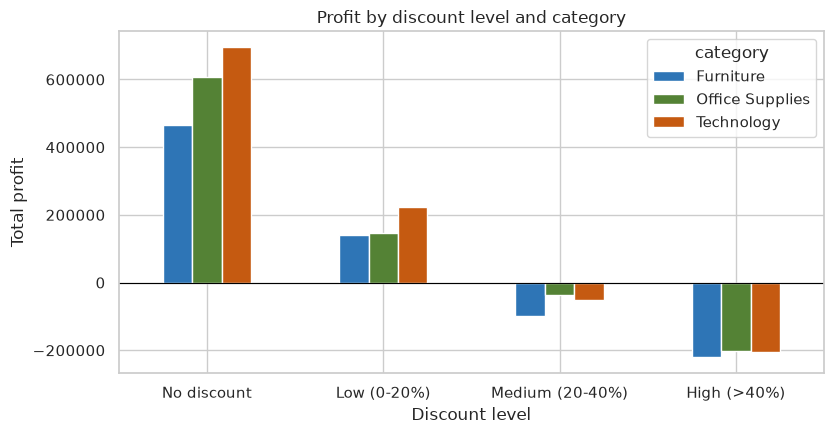

Lines with discount above 20%: 11328 (22.1% of lines, 15.3% of sales)
Profit on those lines: -814682 = -55.5% of total profit

Tables by discount level:


,lines,total_profit
discount_band,,
No discount,208,60447.0
Low (0-20%),186,8011.0
Medium (20-40%),246,-38188.0
High (>40%),221,-94353.0


In [10]:
by_cat = df.pivot_table(index="discount_band", columns="category", values="profit", aggfunc="sum", observed=True)

by_cat.plot(kind="bar", figsize=(8.5, 4.5), color=["#2E75B6", "#548235", "#C55A11"])
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=0); plt.xlabel("Discount level"); plt.ylabel("Total profit")
plt.title("Profit by discount level and category")
plt.tight_layout(); plt.show()

heavy = df[df["discount"] > 0.2]
print("Lines with discount above 20%:", len(heavy), f"({len(heavy)/len(df)*100:.1f}% of lines, {heavy['sales'].sum()/df['sales'].sum()*100:.1f}% of sales)")
print("Profit on those lines:", round(heavy["profit"].sum()), f"= {heavy['profit'].sum()/df['profit'].sum()*100:.1f}% of total profit")
print()
print("Tables by discount level:")
df[df["sub_category"] == "Tables"].groupby("discount_band", observed=True)["profit"].agg(lines="size", total_profit="sum").round(0)

**Insight (discounts):**
- Heavy discounts hurt every category. Lines with a discount above 20% lost 319,763 in Furniture, 257,161 in Technology and 237,759 in Office Supplies, a total of 814,682. That is 55.5% of the total profit of 1,467,457.
- Lines with no discount earned 1,770,695 in profit. The 11,328 lines with discounts above 20% (22.1% of lines but only 15.3% of sales) wipe out almost half of it.
- Tables is not a bad product. At no discount it earns +60,447 and with a small discount +8,011, but it loses 38,188 with a medium discount and 94,353 with a high discount. 54% of its lines were sold with a discount above 20%, so the loss comes from discounting, not from the product.

## 6. Market View

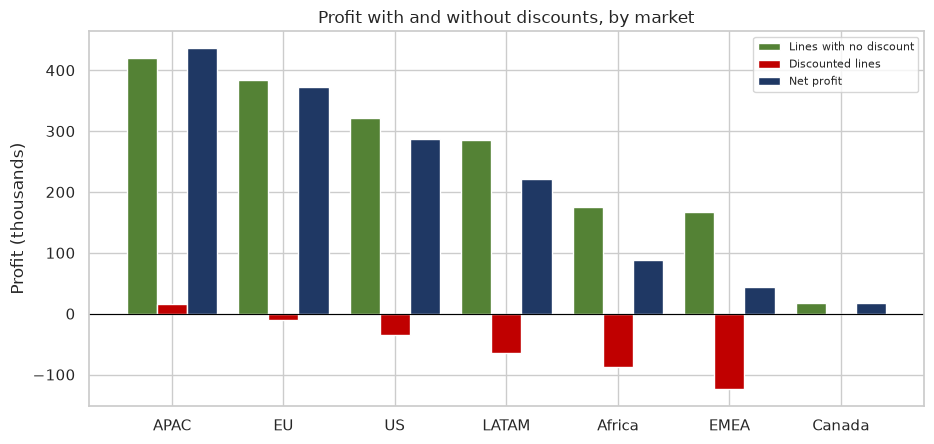

,profit_no_discount,profit_discounted_lines,net_profit,share_lines_over_20pct,avg_discount_when_discounted
market,,,,,
APAC,419629.2,16370.9,436000.0,27.7,25.9
EU,383806.5,-10976.8,372829.7,16.0,26.7
US,320987.6,-34590.6,286397.0,13.9,30.0
LATAM,285625.2,-63981.7,221643.5,25.8,32.9
Africa,175987.1,-87115.5,88871.6,22.3,68.1
EMEA,166842.2,-122944.3,43898.0,32.0,61.3
Canada,17817.4,0.0,17817.4,0.0,0.0


In [11]:
mk = df.groupby("market").apply(lambda g: pd.Series({
    "profit_no_discount": g.loc[g["discount"] == 0, "profit"].sum(),
    "profit_discounted_lines": g.loc[g["discount"] > 0, "profit"].sum(),
    "net_profit": g["profit"].sum(),
    "share_lines_over_20pct": (g["discount"] > 0.2).mean() * 100,
    "avg_discount_when_discounted": g.loc[g["discount"] > 0, "discount"].mean() * 100 if (g["discount"] > 0).any() else 0,
}), include_groups=False).sort_values("net_profit", ascending=False)

x = np.arange(len(mk)); w = 0.27
fig, ax = plt.subplots(figsize=(9.5, 4.6))
ax.bar(x - w, mk["profit_no_discount"] / 1e3, w, label="Lines with no discount", color="#548235")
ax.bar(x, mk["profit_discounted_lines"] / 1e3, w, label="Discounted lines", color="#C00000")
ax.bar(x + w, mk["net_profit"] / 1e3, w, label="Net profit", color="#1F3864")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x); ax.set_xticklabels(mk.index); ax.set_ylabel("Profit (thousands)")
ax.set_title("Profit with and without discounts, by market"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
mk.round(1)

In [12]:
sales_by_year = df.pivot_table(index="market", columns="year", values="sales", aggfunc="sum")
(sales_by_year[2014] / sales_by_year[2011] * 100 - 100).round(0).sort_values(ascending=False).rename("Sales growth 2011 to 2014 (%)")

market
Canada    172.0
Africa    123.0
EMEA      121.0
EU        118.0
APAC       89.0
LATAM      83.0
US         52.0
Name: Sales growth 2011 to 2014 (%), dtype: float64

**Insight (markets):**
- EMEA shows the problem most clearly. Without discounts its lines earn 166,842, but discounted lines lose 122,944, so only 43,898 remains. Discounts erase about 74% of EMEA's profit.
- In EMEA, 32% of lines carry a discount and the average discount on those lines is 61%. This is the highest share of heavy discounting of all markets (APAC 27.7%, LATAM 25.8%, Africa 22.3%, EU 16.0%, US 13.9%).
- Africa has a similar pattern: when it discounts, the average discount is 68%, and its discounted lines lost 87,116.
- Canada gives no discounts at all and has the highest margin (26.6%), but it is very small (66,928 in sales), so it shows what is possible rather than what is easy to copy.
- Growth is strong everywhere, but the US is the slowest: sales grew 52% between 2011 and 2014, compared with 118% in the EU and 121% in EMEA.

## 7. Customer View

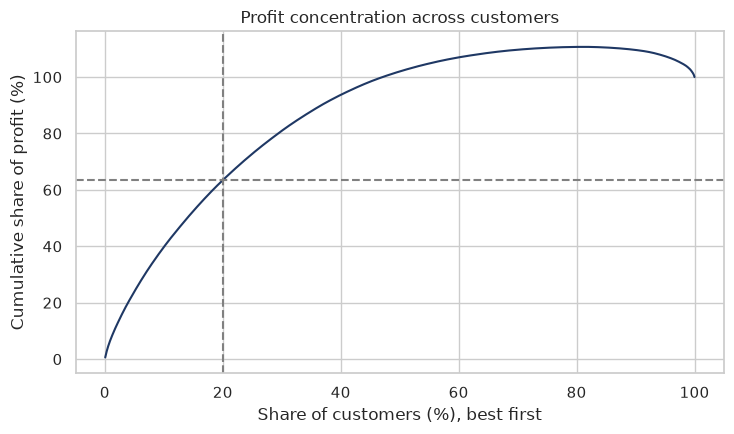

Top 10% of customers: 39.7% of profit
Top 20% of customers: 63.4% of profit
Loss-making customers: 297 of 1590 (18.7%), total -157,135


In [13]:
cust = df.groupby("customer_id")["profit"].sum().sort_values(ascending=False)
cum_share = cust.cumsum() / cust.sum() * 100
cust_pct = np.arange(1, len(cust) + 1) / len(cust) * 100

plt.figure(figsize=(7.5, 4.5))
plt.plot(cust_pct, cum_share.values, color="#1F3864")
plt.axvline(20, color="grey", linestyle="--"); plt.axhline(cum_share.iloc[int(len(cust) * 0.2) - 1], color="grey", linestyle="--")
plt.xlabel("Share of customers (%), best first"); plt.ylabel("Cumulative share of profit (%)")
plt.title("Profit concentration across customers"); plt.tight_layout(); plt.show()

print(f"Top 10% of customers: {cust.head(int(len(cust)*0.1)).sum()/cust.sum()*100:.1f}% of profit")
print(f"Top 20% of customers: {cust.head(int(len(cust)*0.2)).sum()/cust.sum()*100:.1f}% of profit")
print(f"Loss-making customers: {(cust < 0).sum()} of {len(cust)} ({(cust < 0).mean()*100:.1f}%), total {cust[cust < 0].sum():,.0f}")

**Insight (customers):**
- Profit depends on a few customers. The top 10% of customers earn 39.7% of the profit, and the top 20% earn 63.4%.
- 297 customers (18.7% of all) lose money for the business. Together they lost 157,135, so some customers cost more to serve than they bring in.

## 8. Shipping

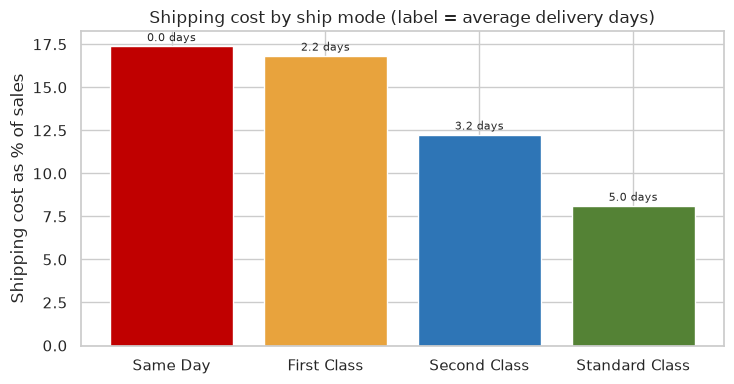

,lines,margin %,shipping cost % of sales,avg_delivery_days
ship_mode,,,,
Same Day,2701,11.42,17.38,0.04
First Class,7505,11.37,16.83,2.18
Second Class,10309,11.40,12.24,3.23
Standard Class,30775,11.75,8.11,5.00


In [14]:
ship = df.groupby("ship_mode").agg(lines=("sales", "size"), sales=("sales", "sum"), profit=("profit", "sum"),
                                   shipping_cost=("shipping_cost", "sum"), avg_delivery_days=("delivery_days", "mean"))
ship["margin %"] = ship["profit"] / ship["sales"] * 100
ship["shipping cost % of sales"] = ship["shipping_cost"] / ship["sales"] * 100
ship = ship.sort_values("avg_delivery_days")

plt.figure(figsize=(7.5, 4))
bars = plt.bar(ship.index, ship["shipping cost % of sales"], color=["#C00000", "#E8A33D", "#2E75B6", "#548235"])
for b, d in zip(bars, ship["avg_delivery_days"]):
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.3, f"{d:.1f} days", ha="center", fontsize=8)
plt.ylabel("Shipping cost as % of sales"); plt.title("Shipping cost by ship mode (label = average delivery days)")
plt.tight_layout(); plt.show()
ship[["lines", "margin %", "shipping cost % of sales", "avg_delivery_days"]].round(2)

**Insight (shipping):**
- Shipping margins are almost the same for all four modes (11.4% to 11.8%), but shipping cost is very different compared with sales: 17.4% for Same Day and 16.8% for First Class, against 8.1% for Standard Class.
- Standard Class is 60% of all lines. Same Day and First Class are expensive to run and are worth reviewing. The data does not say whether customers pay for shipping, so this needs to be confirmed with Finance.

## 9. Opportunity: What Is It Worth?

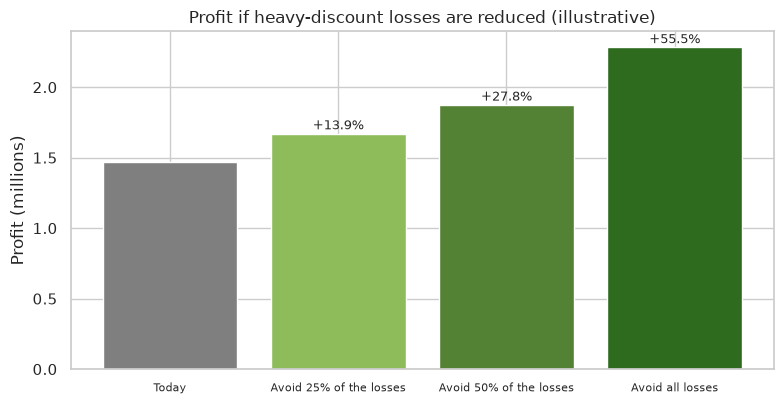

,Scenario,Profit,Change vs today (%)
0,Today,1467457.0,0.0
1,Avoid 25% of the losses,1671128.0,13.9
2,Avoid 50% of the losses,1874798.0,27.8
3,Avoid all losses,2282139.0,55.5


In [15]:
current = df["profit"].sum()
heavy_loss = -df.loc[df["discount"] > 0.2, "profit"].sum()

scenarios = pd.DataFrame({
    "Scenario": ["Today", "Avoid 25% of the losses", "Avoid 50% of the losses", "Avoid all losses"],
    "Profit": [current, current + 0.25 * heavy_loss, current + 0.5 * heavy_loss, current + heavy_loss],
})
scenarios["Change vs today (%)"] = (scenarios["Profit"] / current * 100 - 100).round(1)

plt.figure(figsize=(8, 4.2))
bars = plt.bar(scenarios["Scenario"], scenarios["Profit"] / 1e6, color=["#7F7F7F", "#8FBC5A", "#548235", "#2E6B1F"])
for b, p in zip(bars, scenarios["Change vs today (%)"]):
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.03, f"{p:+.1f}%" if p else "", ha="center", fontsize=9)
plt.ylabel("Profit (millions)"); plt.title("Profit if heavy-discount losses are reduced (illustrative)")
plt.xticks(fontsize=8); plt.tight_layout(); plt.show()
scenarios.round({"Profit": 0, "Change vs today (%)": 1})

**Insight (opportunity):**
- Lines with a discount above 20% lose 814,682 in total. Even if every one of those sales were lost, profit would rise by 814,682 (+55.5%) while sales would fall by 1.93M (15.3%).
- A more realistic case is to avoid a quarter to a half of these losses, which adds about 203,671 to 407,341 in profit (+13.9% to +27.8%).
- These are illustrative figures. They assume the sales that remain behave as they do today, and the data cannot show how many customers would stop buying without a discount.

## 10. Recommendations

In [16]:
recs = pd.DataFrame([
    ["1", "High", "Cap discounts at 20%; discounts above 20% need Sales Director and Finance approval", "Sales Director", "30 days", "Adds about 204K to 407K profit (25% to 50% of heavy-discount losses avoided)", "Lines with discount above 20%: from 22.1% to under 5%"],
    ["2", "High", "Stop discounts above 20% on Tables", "Furniture product manager", "30 days", "Removes a 132,541 loss on Tables; the product is profitable at full price", "Tables margin from -8.5% to above 0%"],
    ["3", "High", "Reset the EMEA and Africa discount policy (EMEA: 32% of lines discounted at 61% on average; Africa: 68% average)", "EMEA and Africa regional managers", "60 days", "Halving the combined 210,060 loss on discounted lines adds about 105K", "EMEA margin from 5.4% to 10% or more"],
    ["4", "Medium", "Protect the top 10% of customers and review the 297 loss-making ones", "Sales operations", "90 days", "Protects 39.7% of profit; reduces a 157,135 loss", "Loss-making customers from 297 to about 200"],
    ["5", "Medium", "Prepare for the September to December peak (45% of sales)", "Operations", "Start in August", "Avoids stock and delivery problems in the busiest months", "On-time delivery in Q4"],
    ["6", "Medium", "Review pricing of Same Day and First Class shipping (about 17% of sales vs 8%)", "Logistics and Finance", "90 days", "Confirms whether fast shipping is paid for by customers", "Shipping cost % of sales for fast modes"],
    ["7", "Medium", "Track five KPIs on a monthly dashboard (sales, profit margin, heavy-discount share, loss-making lines, top-customer profit)", "BI team", "60 days", "Keeps the changes visible and on track", "Dashboard reviewed monthly"],
], columns=["No.", "Priority", "Action", "Owner", "Timeline", "Expected impact", "KPI to track"])
recs

,No.,Priority,Action,Owner,Timeline,Expected impact,KPI to track
0,1,High,Cap discounts at 20%; discounts above 20% need...,Sales Director,30 days,Adds about 204K to 407K profit (25% to 50% of ...,Lines with discount above 20%: from 22.1% to u...
1,2,High,Stop discounts above 20% on Tables,Furniture product manager,30 days,"Removes a 132,541 loss on Tables; the product ...",Tables margin from -8.5% to above 0%
2,3,High,Reset the EMEA and Africa discount policy (EME...,EMEA and Africa regional managers,60 days,"Halving the combined 210,060 loss on discounte...",EMEA margin from 5.4% to 10% or more
3,4,Medium,Protect the top 10% of customers and review th...,Sales operations,90 days,"Protects 39.7% of profit; reduces a 157,135 loss",Loss-making customers from 297 to about 200
4,5,Medium,Prepare for the September to December peak (45...,Operations,Start in August,Avoids stock and delivery problems in the busi...,On-time delivery in Q4
5,6,Medium,Review pricing of Same Day and First Class shi...,Logistics and Finance,90 days,Confirms whether fast shipping is paid for by ...,Shipping cost % of sales for fast modes
6,7,Medium,"Track five KPIs on a monthly dashboard (sales,...",BI team,60 days,Keeps the changes visible and on track,Dashboard reviewed monthly


## 11. Conclusion
**Main finding:** the business is growing well (sales +90%, profit +102% from 2011 to 2014), but heavy discounting is quietly destroying value. Lines with a discount above 20% lost 814,682, which is 55.5% of total profit. The loss appears in every category and every market, and it is largest where discounts are most aggressive (EMEA). Tables, the only loss-making sub-category, is profitable at full price.

**What to do:** cap discounts at 20% with an approval rule, stop heavy discounts on Tables, reset the EMEA policy, protect the best customers, prepare for the Q4 peak, and track the KPIs monthly.

**Limits of this analysis:** the data covers 2011 to 2014 only; it cannot prove that discounts cause the losses (product mix and customer behaviour also matter); the opportunity figures are illustrative; and the data does not say whether shipping costs are charged to customers.

**Next steps:** run the 20% cap as a 3-month pilot in two markets, compare with matching markets, and decide on a full rollout using the pilot results.